In [2]:
# Logistic Regression - Binary Classification
# Datasets:
#   - Titanic: ../Datasets/Titanic-Dataset.csv
#   - Heart Disease UCI: ../Datasets/heart.csv
#     https://archive.ics.uci.edu/dataset/45/heart+disease
#     (also on Kaggle: https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score
)


Accuracy: 0.8044692737430168

Confusion Matrix:
 [[98 12]
 [23 46]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



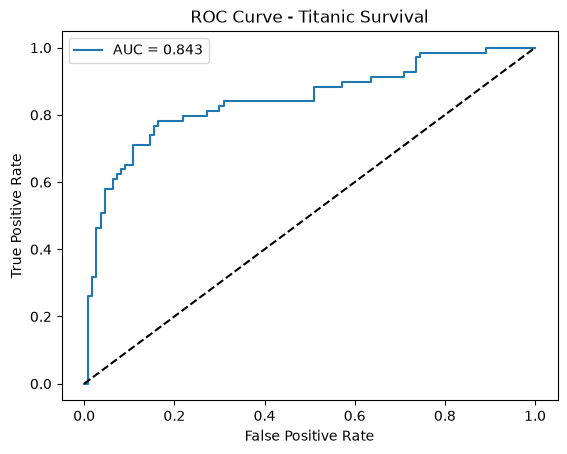

      Feature  Coefficient
1         Sex     1.269598
0      Pclass    -0.928698
2         Age    -0.502878
3       SibSp    -0.262672
7  Embarked_S    -0.171784
5        Fare     0.099599
6  Embarked_Q     0.080683
4       Parch    -0.067158


In [3]:
# ============================================================
# PART 1 - Titanic (predict Survived)
# ============================================================

df = pd.read_csv(r"C:\My-Data-Science-Portfolio\Datasets\Titanic-Dataset.csv")

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked_Q", "Embarked_S"]
X = df[features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ---- 1. Fit logistic regression ----
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_scaled, y_train)

# ---- 2. Predict class labels AND probabilities ----
y_pred = clf.predict(X_test_scaled)
y_proba = clf.predict_proba(X_test_scaled)[:, 1]   # probability of class 1 (Survived)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 3. ROC curve and AUC ----
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")   # random guess baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Titanic Survival")
plt.legend()
plt.show()

# ---- 4. Coefficients - direction and strength of each feature's effect ----
coef_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": clf.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False)
print(coef_df)

# positive coefficient = pushes probability of survival up
# negative coefficient = pushes it down
# e.g. Sex (female=1) usually has a strong positive coefficient

In [5]:
# ============================================================
# PART 2 - Heart Disease UCI (predict presence of heart disease)
# ============================================================

heart = pd.read_csv(r"C:\Users\syin\Downloads\heart+disease")

print(heart.shape)
print(heart.head())
print(heart.isnull().sum())

# target column is usually named "target" (0 = no disease, 1 = disease)
# some versions use values 0-4 for severity - simplify to binary if needed:
if heart["target"].nunique() > 2:
    heart["target"] = (heart["target"] > 0).astype(int)

print(heart["target"].value_counts())

Xh = heart.drop(columns=["target"])
yh = heart["target"]

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    Xh, yh, test_size=0.2, random_state=42, stratify=yh
)

# ---- 5. Scale and fit ----
scaler2 = StandardScaler()
Xh_train_scaled = scaler2.fit_transform(Xh_train)
Xh_test_scaled = scaler2.transform(Xh_test)
clf2 = LogisticRegression(max_iter=1000, random_state=42)
clf2.fit(Xh_train_scaled, yh_train)

# ---- 6. Predict and evaluate ----
yh_pred = clf2.predict(Xh_test_scaled)
yh_proba = clf2.predict_proba(Xh_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(yh_test, yh_pred))
print("\nConfusion Matrix:\n", confusion_matrix(yh_test, yh_pred))
print("\nClassification Report:\n", classification_report(yh_test, yh_pred))
print("AUC:", roc_auc_score(yh_test, yh_proba))

# ---- 7. Feature importance via coefficients ----
coef_heart = pd.DataFrame({
    "Feature": Xh.columns,
    "Coefficient": clf2.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False)
print(coef_heart)

sns.barplot(x="Coefficient", y="Feature", data=coef_heart)
plt.title("Logistic Regression Coefficients - Heart Disease")
plt.show()

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\syin\\Downloads\\heart+disease'